# 12 - Model Validation

Final validation of the scorecard (champion) against the LightGBM challengers on the test set. No model is changed or refit.

| Axis | Question | Metrics |
|---|---|---|
| **Discrimination** | Does the model separate goods from bads? | AUC, Gini, KS, PR-AUC, bootstrap 95% CI of Gini |
| **Rank ordering** | Are bads concentrated at the top of the risk ranking? | Gain chart, lift chart |
| **Calibration** | Do predicted PDs match observed default rates? | Mean PD vs default rate per decile |
| **Stability** | Has the population shifted between train and test? | CSI per scorecard feature (score PSI already in `08_scorecard`) |

## 1. Setup

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd

# Add project root to sys.path so `src` can be imported from the notebooks/ folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.evaluation import (
    bootstrap_gini,
    calibration_table,
    csi,
    gains_table,
    percentile_ci,
    performance_summary,
    pr_auc,
)
from src.woe import bin_frame

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
N_BOOT = 500

# Chart colors: categorical slots 1-4 in fixed order (same as 09_lightgbm), muted ink for reference lines
COLORS = {"Scorecard": "#2a78d6", "LGBM-16": "#eb6834", "LGBM-16-mono": "#1baf7a", "LGBM-full": "#eda100"}
MUTED, GRID = "#8a8985", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
})

## 2. Load test predictions

PDs of all four models on the test set, saved by `09_lightgbm`.

In [2]:
pd_all = pd.read_pickle(DATA_DIR / "pd_test_all_models.pkl")
y_test = pd_all.pop("TARGET")
models = list(COLORS)
pd_all = pd_all[models]
base_rate = y_test.mean()
print(f"Test: {len(y_test):,} rows | default rate {base_rate:.2%} | models: {models}")

Test: 61,503 rows | default rate 8.07% | models: ['Scorecard', 'LGBM-16', 'LGBM-16-mono', 'LGBM-full']


## 3. Discrimination

PR-AUC focuses on the bad class; with 8% defaults a random model scores the default rate (≈ 0.081), not 0.5. `pr_auc_lift` = PR-AUC / default rate.

In [3]:
summary = pd.DataFrame({
    m: pd.concat([performance_summary(y_test, pd_all[m]), pd.Series({"pr_auc": pr_auc(y_test, pd_all[m])})])
    for m in models
}).T
summary["pr_auc_lift"] = summary["pr_auc"] / base_rate
summary.round(4)

,auc,gini,ks,pr_auc,pr_auc_lift
Scorecard,0.7386,0.4772,0.3572,0.2160,2.6761
LGBM-16,0.7509,0.5017,0.3730,0.2394,2.9650
LGBM-16-mono,0.7457,0.4913,0.3634,0.2296,2.8446
LGBM-full,0.7592,0.5183,0.3913,0.2495,3.0907


### Bootstrap 95% CI of Gini

Paired bootstrap: every model is scored on the same resample, so the CI of the **difference vs Scorecard** is valid. If that CI excludes 0, the challenger's gain is not just sampling noise.

In [4]:
samples = bootstrap_gini(y_test, pd_all, n_boot=N_BOOT, seed=0)
gini_ci = percentile_ci(samples).add_prefix("gini_")
diff = samples.drop(columns="Scorecard").sub(samples["Scorecard"], axis=0)
diff_ci = percentile_ci(diff).add_prefix("gain_vs_scorecard_")

summary = summary.join(gini_ci).join(diff_ci)
summary[["gini", "gini_lower", "gini_upper", "gain_vs_scorecard_lower", "gain_vs_scorecard_upper"]].round(4)

,gini,gini_lower,gini_upper,gain_vs_scorecard_lower,gain_vs_scorecard_upper
Scorecard,0.4772,0.4639,0.4896,NaN,NaN
LGBM-16,0.5017,0.4881,0.5152,0.0196,0.0304
LGBM-16-mono,0.4913,0.4773,0.5045,0.0102,0.0181
LGBM-full,0.5183,0.5053,0.5310,0.0353,0.0482


## 4. Rank ordering: gain and lift charts

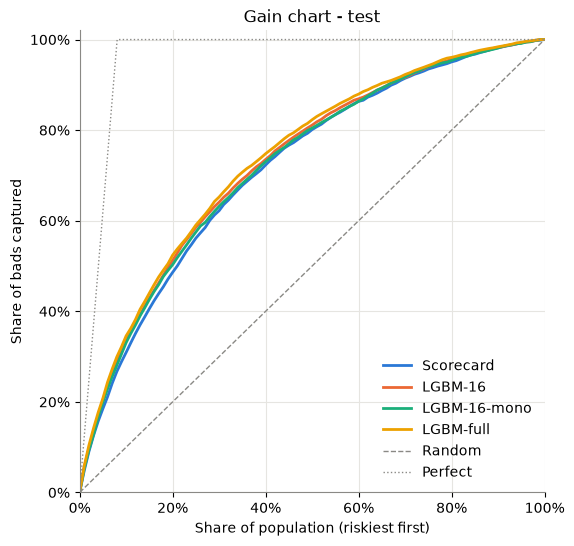

In [5]:
fine = {m: gains_table(y_test, pd_all[m], n_bins=100) for m in models}
deciles = {m: gains_table(y_test, pd_all[m], n_bins=10) for m in models}

fig, ax = plt.subplots(figsize=(6, 6))
for m in models:
    t = fine[m]
    ax.plot([0, *t["cum_pop_pct"]], [0, *t["cum_bad_pct"]], color=COLORS[m], label=m)
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Random")
ax.plot([0, base_rate, 1], [0, 1, 1], color=MUTED, linestyle=":", linewidth=1, label="Perfect")
ax.set(xlabel="Share of population (riskiest first)", ylabel="Share of bads captured",
       title="Gain chart - test", xlim=(0, 1), ylim=(0, 1.02))
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc="lower right", frameon=False)
fig.savefig(OUTPUT_DIR / "gain_chart.png", dpi=150, bbox_inches="tight")
plt.show()

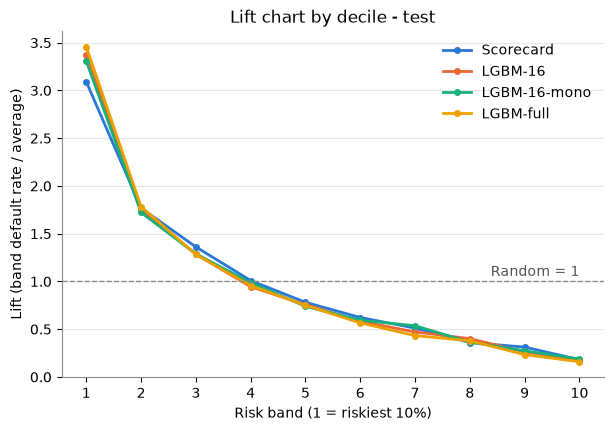

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in models:
    t = deciles[m]
    ax.plot(t.index, t["lift"], color=COLORS[m], marker="o", markersize=4, label=m)
ax.axhline(1, color=MUTED, linestyle="--", linewidth=1)
ax.annotate("Random = 1", (10, 1), xytext=(0, 4), textcoords="offset points", ha="right", color="#52514e")
ax.set(xlabel="Risk band (1 = riskiest 10%)", ylabel="Lift (band default rate / average)",
       title="Lift chart by decile - test", xticks=range(1, 11))
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
fig.savefig(OUTPUT_DIR / "lift_chart.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Share of bads captured and cumulative lift at typical review depths
depth = pd.DataFrame({
    m: {f"top {k}0%": deciles[m].loc[k, "cum_bad_pct"] for k in (1, 2, 3)}
    | {f"cum_lift top {k}0%": deciles[m].loc[k, "cum_lift"] for k in (1, 2, 3)}
    for m in models
}).T
depth.round(3)

,top 10%,top 20%,top 30%,cum_lift top 10%,cum_lift top 20%,cum_lift top 30%
Scorecard,0.309,0.486,0.622,3.091,2.430,2.074
LGBM-16,0.337,0.512,0.641,3.369,2.562,2.136
LGBM-16-mono,0.331,0.503,0.632,3.307,2.515,2.106
LGBM-full,0.346,0.524,0.652,3.458,2.620,2.175


## 5. Calibration

Mean predicted PD vs observed default rate per decile. Points on the diagonal = well calibrated.

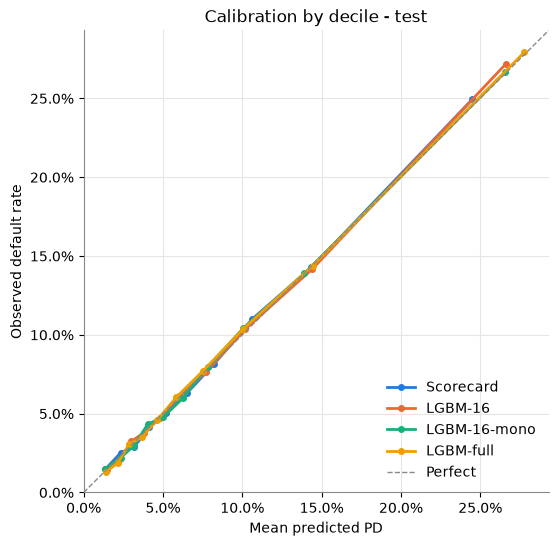

,Scorecard,LGBM-16,LGBM-16-mono,LGBM-full
band,,,,
1,1.018,1.022,1.004,1.005
2,0.995,0.983,0.999,0.997
3,1.036,1.017,1.036,1.031
4,0.990,0.988,1.018,1.025
5,0.968,1.013,0.956,1.034
6,0.967,0.981,0.953,0.990
7,1.002,0.999,1.073,0.956
8,0.909,1.078,0.932,1.065
9,1.078,0.925,0.949,0.870


In [8]:
calib = {m: calibration_table(y_test, pd_all[m]) for m in models}

fig, ax = plt.subplots(figsize=(6, 6))
top = max(max(c["mean_pd"].max(), c["bad_rate"].max()) for c in calib.values()) * 1.05
for m in models:
    ax.plot(calib[m]["mean_pd"], calib[m]["bad_rate"], color=COLORS[m], marker="o", markersize=4, label=m)
ax.plot([0, top], [0, top], color=MUTED, linestyle="--", linewidth=1, label="Perfect")
ax.set(xlabel="Mean predicted PD", ylabel="Observed default rate", title="Calibration by decile - test",
       xlim=(0, top), ylim=(0, top))
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc="lower right", frameon=False)
fig.savefig(OUTPUT_DIR / "calibration_chart.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({m: c["ratio"] for m, c in calib.items()}).round(3)

## 6. Stability: CSI per scorecard feature

Share of each WoE bin on train vs test. Thresholds as PSI: < 0.1 stable, 0.1-0.25 monitor, > 0.25 significant shift.

In [9]:
with open(OUTPUT_DIR / "woe_spec_final.pkl", "rb") as f:
    woe_spec = pickle.load(f)
features = pd.read_csv(OUTPUT_DIR / "model_features.csv")["feature"].tolist()
spec = {f: woe_spec[f] for f in features}

binned_train = bin_frame(pd.read_pickle(DATA_DIR / "train.pkl"), spec)
binned_test = bin_frame(pd.read_pickle(DATA_DIR / "test.pkl"), spec)

csi_table = (
    pd.Series({f: csi(binned_train[f], binned_test[f]) for f in features}, name="csi")
    .sort_values(ascending=False)
    .to_frame()
)
csi_table["status"] = pd.cut(csi_table["csi"], [-1, 0.1, 0.25, float("inf")], labels=["stable", "monitor", "shift"])
scaling = pd.read_csv(OUTPUT_DIR / "score_scaling.csv", index_col=0).iloc[:, 0]
print(f"Score PSI train vs test (08_scorecard): {scaling['psi_train_test']:.4f}")
csi_table.round(5)

Score PSI train vs test (08_scorecard): 0.0002


,csi,status
YEARS_REGISTRATION,0.00038,stable
ORGANIZATION_TYPE,0.00037,stable
EXT_SOURCE_1,0.00034,stable
EXT_SOURCE_3,0.00028,stable
YEARS_ID_PUBLISH,0.00021,stable
OCCUPATION_TYPE,0.00020,stable
YEARS_LAST_PHONE_CHANGE,0.00019,stable
YEARS_EMPLOYED,0.00017,stable
NAME_EDUCATION_TYPE,0.00013,stable
EXT_SOURCE_2,0.00013,stable


## 7. Save artifacts

In [10]:
summary.to_csv(OUTPUT_DIR / "validation_summary.csv")
samples.to_csv(OUTPUT_DIR / "bootstrap_gini.csv", index=False)
csi_table.to_csv(OUTPUT_DIR / "csi.csv")
print("Saved validation_summary.csv, bootstrap_gini.csv, csi.csv, gain_chart.png, lift_chart.png, calibration_chart.png")

Saved validation_summary.csv, bootstrap_gini.csv, csi.csv, gain_chart.png, lift_chart.png, calibration_chart.png


## 8. Conclusions

**Discrimination.** Scorecard Gini 0.477 (95% CI 0.464-0.490), KS 0.357, PR-AUC 0.216 = 2.7× the random baseline (0.081). All challengers beat it and every paired CI of the gain excludes 0, so the gains are real, but small:

| Challenger | Gini gain vs Scorecard (95% CI) |
|---|---|
| LGBM-16-mono | +0.014 (0.010-0.018) |
| LGBM-16 | +0.025 (0.020-0.030) |
| LGBM-full | +0.041 (0.035-0.048) |

**Rank ordering.** Lift falls monotonically across deciles for all models. The scorecard's riskiest 10% has 3.1× the average default rate; its top 30% captures 62% of bads (LGBM-full 65%). The gain curves almost overlap: the challengers' edge sits mainly in the first decile (lift 3.3-3.5 vs 3.1).

**Calibration.** All models lie on the diagonal; decile ratios 0.87-1.12 (scorecard 0.91-1.08). Predicted PDs can be used directly for pricing / expected loss.

**Stability.** Every scorecard feature has CSI < 0.001 and score PSI is 0.0002, far below the 0.1 threshold. Expected for a random split; real monitoring needs out-of-time data.

**Verdict.** The scorecard is validated as champion: acceptable discrimination (Gini > 0.4, KS > 0.3), well calibrated, stable and fully explainable. LGBM-full's +0.04 Gini is statistically significant but comes with 119 features, uses age and gives harder-to-defend local explanations (`10_shap`); it remains a benchmark challenger.